In [1]:

import numpy as np
import pandas as pd
from pathlib import Path

# Project data location
DATA_PATH = Path("../data/raw")
PROCESSED_PATH = Path("../data/processed")

PROCESSED_PATH.mkdir(parents=True, exist_ok=True)

# Column names
columns = (
    ["unit_id", "cycle"]
    + [f"setting_{i}" for i in range(1, 4)]
    + [f"sensor_{i}" for i in range(1, 22)]
)

# Load original NASA training dataset
train_df = pd.read_csv(
    DATA_PATH / "train_FD001.txt",
    sep=r"\s+",
    header=None,
    names=columns
)

print("Dataset loaded successfully!")
print("Shape:", train_df.shape)


Dataset loaded successfully!
Shape: (20631, 26)


In [2]:

# Find the final observed cycle of every engine

max_cycles = (
    train_df.groupby("unit_id")["cycle"]
    .max()
    .reset_index()
)

max_cycles.columns = ["unit_id", "max_cycle"]

display(max_cycles.head())

print("Number of engines:", len(max_cycles))


,unit_id,max_cycle
0,1,192
1,2,287
2,3,179
3,4,189
4,5,269


Number of engines: 100


In [3]:

# Merge maximum cycle information into training data

train_df = train_df.merge(
    max_cycles,
    on="unit_id",
    how="left",
    validate="many_to_one"
)

# Calculate Remaining Useful Life

train_df["RUL"] = (
    train_df["max_cycle"] - train_df["cycle"]
)

print("RUL labels created successfully!")

display(
    train_df[
        ["unit_id", "cycle", "max_cycle", "RUL"]
    ].head(10)
)


RUL labels created successfully!


,unit_id,cycle,max_cycle,RUL
0,1,1,192,191
1,1,2,192,190
2,1,3,192,189
3,1,4,192,188
4,1,5,192,187
5,1,6,192,186
6,1,7,192,185
7,1,8,192,184
8,1,9,192,183
9,1,10,192,182


In [4]:

# Every engine's last training observation should have RUL = 0

last_observations = (
    train_df.sort_values("cycle")
    .groupby("unit_id")
    .tail(1)
)

assert (last_observations["RUL"] == 0).all()

# RUL should never be negative
assert (train_df["RUL"] >= 0).all()

# No missing RUL values
assert train_df["RUL"].notna().all()

# RUL must decrease as cycle increases for each engine
rul_differences = (
    train_df.sort_values(["unit_id", "cycle"])
    .groupby("unit_id")["RUL"]
    .diff()
    .dropna()
)

assert (rul_differences < 0).all()

print("All RUL validation checks passed!")


All RUL validation checks passed!


RUL Statistics:


count    20631.000000
mean       107.807862
std         68.880990
min          0.000000
25%         51.000000
50%        103.000000
75%        155.000000
max        361.000000
Name: RUL, dtype: float64


Minimum RUL: 0
Maximum RUL: 361

RUL Distribution:


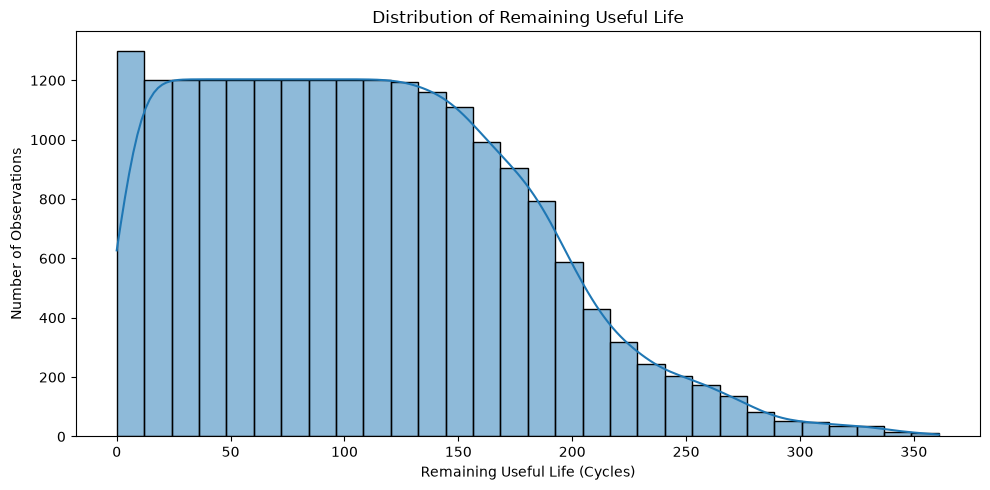

In [5]:

print("RUL Statistics:")
display(train_df["RUL"].describe())

print("\nMinimum RUL:", train_df["RUL"].min())
print("Maximum RUL:", train_df["RUL"].max())

print("\nRUL Distribution:")

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.histplot(
    data=train_df,
    x="RUL",
    bins=30,
    kde=True
)

plt.title("Distribution of Remaining Useful Life")
plt.xlabel("Remaining Useful Life (Cycles)")
plt.ylabel("Number of Observations")

plt.tight_layout()
plt.show()


In [6]:

# Save processed training dataset

output_path = PROCESSED_PATH / "train_FD001_with_RUL.csv"

train_df.to_csv(output_path, index=False)

print("Processed dataset saved successfully!")
print("Location:", output_path)
print("Final shape:", train_df.shape)


Processed dataset saved successfully!
Location: ..\data\processed\train_FD001_with_RUL.csv
Final shape: (20631, 28)
